# 5 · Aprender cuando los demás también aprenden

**Lectura acompañada:** §§5.1–5.3, pp. 121–146 de [Murphy, v5](https://arxiv.org/abs/2412.05265v5). Necesitas distribuciones discretas, esperanza y multiplicación de matrices.

**Objetivo:** distinguir rendimiento frente a un rival, robustez y equilibrio. Construiremos juegos, calcularemos mejores respuestas y entrenaremos dos jugadores mediante regret matching. También veremos por qué información centralizada y ejecución local son condiciones diferentes.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})


## 1. §5.1 · El entorno contiene decisiones ajenas

En un MDP de un agente, las reglas del entorno se mantienen fijas mientras aprende. En un juego, otro jugador puede cambiar su política simultáneamente. Para el primero cambia la distribución efectiva de lo que sucederá, incluso si las reglas físicas son las mismas.

Un juego de forma normal describe acciones conjuntas y pagos. Un juego estocástico añade estados y transiciones. Un POSG añade observaciones parciales. En forma extensiva representamos orden de decisiones e información: un conjunto de información agrupa historias que un jugador no puede distinguir.

Las recompensas pueden coincidir, sumar cero o tener intereses mixtos. Por eso no existe una única noción de «mejor política» que ignore a los demás.

En piedra, papel y tijera usamos una matriz A para el pago del jugador de filas. El jugador de columnas recibe el opuesto. Si las distribuciones son p y q, el pago esperado es $p^\top A q$.


In [2]:
A = np.array([[0.0, -1.0, 1.0],
              [1.0, 0.0, -1.0],
              [-1.0, 1.0, 0.0]])
nombres = ["Piedra", "Papel", "Tijera"]
uniforme = np.ones(3)/3
p = np.array([0.8, 0.1, 0.1])
q = np.array([1.0, 0.0, 0.0])
print("Pago de p contra piedra:", p @ A @ q)
print("Pago de cada acción contra piedra:", A @ q)
print("Mejor respuesta:", nombres[int(np.argmax(A @ q))])
np.testing.assert_allclose(A, -A.T)


Pago de p contra piedra: 0.0
Pago de cada acción contra piedra: [ 0.  1. -1.]
Mejor respuesta: Papel


Si q cambia, la mejor respuesta también. Un aprendiz independiente puede perseguir una distribución que ya ha dejado de existir cuando termina de estimarla.

## 2. §5.2 · Empatar no certifica equilibrio

Una mejor respuesta maximiza el pago frente a una política rival fija. Un equilibrio de Nash exige que ningún jugador mejore cambiando unilateralmente, manteniendo las políticas de los demás.

Para dos jugadores de suma cero, medimos la suma de incentivos a desviarse:

$$\mathrm{NashConv}(p,q)=\max_i(Aq)_i-\min_j(p^\top A)_j.$$

El pago actual desaparece al sumar las dos mejoras. Algunas definiciones de explotabilidad dividen entre dos; aquí usamos la suma completa. Una pareja que siempre juega piedra empata, pero ambos tienen incentivos a cambiar.


In [3]:
def nashconv(p, q):
    pago = float(p @ A @ q)
    mejora_filas = float(np.max(A @ q) - pago)
    mejora_columnas = float(pago - np.min(p @ A))
    return mejora_filas + mejora_columnas

piedra = np.array([1.0, 0.0, 0.0])
for p, q, etiqueta in [(piedra, piedra, "Piedra frente a piedra"),
                       (uniforme, uniforme, "Uniforme frente a uniforme")]:
    print(etiqueta, "pago:", p @ A @ q, "NashConv:", nashconv(p, q))
assert np.isclose(nashconv(uniforme, uniforme), 0)
assert np.isclose(nashconv(piedra, piedra), 2)


Piedra frente a piedra pago: 0.0 NashConv: 2.0
Uniforme frente a uniforme pago: 0.0 NashConv: 0.0


En suma cero, minimax busca protegerse contra el peor rival. Explotar una debilidad concreta y protegerse contra cualquier rival son objetivos distintos. Una política puede ganar mucho en su distribución habitual de oponentes y fallar contra una mejor respuesta.

## 3. Nash no significa bienestar social

En el dilema del prisionero, cada jugador puede preferir desertar, aunque ambos estarían mejor cooperando. Es un ejemplo de suma general: ya no basta una matriz y su negativo.

Pareto, bienestar y equidad responden preguntas distintas. Un equilibrio de Nash puede ser ineficiente, y un resultado Pareto eficiente no tiene por qué ser estable frente a desviaciones individuales. En Stackelberg importa además quién puede comprometerse primero y cómo responde el seguidor.


In [4]:
# Índices: 0 cooperar, 1 desertar.
U1 = np.array([[3.0, 0.0], [5.0, 1.0]])
U2 = np.array([[3.0, 5.0], [0.0, 1.0]])
equilibrios = []
for i in range(2):
    for j in range(2):
        if U1[i, j] >= U1[:, j].max() and U2[i, j] >= U2[i, :].max():
            equilibrios.append((i, j))
print("Equilibrios puros:", equilibrios)
print("Cooperar ambos:", U1[0, 0], U2[0, 0])
print("Desertar ambos:", U1[1, 1], U2[1, 1])
assert equilibrios == [(1, 1)]


Equilibrios puros: [(1, 1)]
Cooperar ambos: 3.0 3.0
Desertar ambos: 1.0 1.0


## 4. Correlación: compartir una señal puede cambiar lo posible

Dos jugadores quieren elegir la misma puerta. Si cada uno lanza su propia moneda, coordinan la mitad de las veces. Una moneda común permite seleccionar juntos una de las dos puertas. Conservar las mismas distribuciones marginales no conserva la distribución conjunta.

Un equilibrio correlacionado permite recomendaciones basadas en una señal común, con restricciones para que no convenga desobedecer la propia recomendación. No toda distribución correlacionada es un equilibrio: deben verificarse esos incentivos. En este juego de coordinación, seguir una recomendación común sí los satisface.


Acierto independiente: 0.4936
Acierto con señal común: 1.0


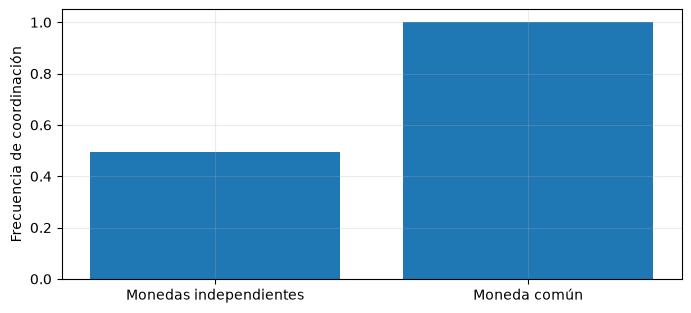

In [5]:
rng = np.random.default_rng(SEMILLA)
n = 10000
eleccion_1 = rng.integers(0, 2, n)
eleccion_2_independiente = rng.integers(0, 2, n)
eleccion_2_comun = eleccion_1.copy()
print("Acierto independiente:", np.mean(eleccion_1 == eleccion_2_independiente))
print("Acierto con señal común:", np.mean(eleccion_1 == eleccion_2_comun))
plt.bar(["Monedas independientes", "Moneda común"],
        [np.mean(eleccion_1 == eleccion_2_independiente), 1])
plt.ylabel("Frecuencia de coordinación")
plt.show()


Para atribuir valor a contribuciones cooperativas, Shapley promedia el aporte marginal de un jugador sobre órdenes de incorporación. Eso tampoco es una regla de equilibrio. Si dos participantes valen 1 y 2 por separado y 6 juntos, la complementariedad debe repartirse según un criterio declarado.


In [6]:
v_vacio, v_uno, v_dos, v_ambos = 0, 1, 2, 6
shapley_1 = 0.5*(v_uno-v_vacio) + 0.5*(v_ambos-v_dos)
shapley_2 = 0.5*(v_dos-v_vacio) + 0.5*(v_ambos-v_uno)
print("Contribuciones Shapley:", shapley_1, shapley_2)
assert shapley_1 + shapley_2 == v_ambos-v_vacio


Contribuciones Shapley: 2.5 3.5


## 5. §5.3 · Arrepentimiento: aprender de lo que podríamos haber hecho

El arrepentimiento externo compara el pago acumulado con haber usado siempre una acción alternativa. En regret matching asignamos probabilidad proporcional a la parte positiva del arrepentimiento acumulado. Si no hay parte positiva, usamos uniforme.

Aquí calculamos los pagos esperados de todas las acciones contra la distribución rival. Es información completa. Si solo observásemos la recompensa de la acción elegida, harían falta estimadores adicionales; no sería exactamente este algoritmo.


In [7]:
def estrategia(regrets):
    positivos = np.maximum(regrets, 0)
    return positivos/positivos.sum() if positivos.sum() > 0 else np.ones(3)/3

regrets = np.array([2.0, -1.0, 1.0])
print("Probabilidades por regret matching:", estrategia(regrets))
np.testing.assert_allclose(estrategia(regrets), [2/3, 0, 1/3])


Probabilidades por regret matching: [0.6667 0.     0.3333]


La siguiente función actualiza a ambos jugadores usando sus políticas anteriores. Si actualizásemos el segundo después de cambiar el primero, habríamos definido otra dinámica.

Además guardamos dos objetos diferentes: la política usada ahora y la media temporal de las políticas ya utilizadas. Los resultados de ausencia de arrepentimiento en suma cero se relacionan con estas medias; no exigen que la última política deje de oscilar.


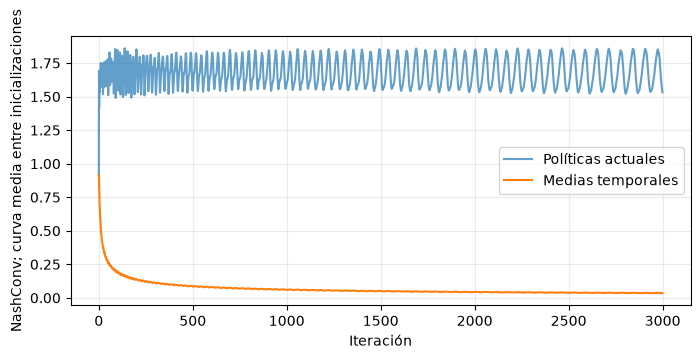

NashConv final de políticas actuales: 1.5313279895909133
NashConv final de medias temporales: 0.03492079816572756
Media temporal del jugador 1, primera ejecución: [0.3274 0.3301 0.3426]


In [8]:
def aprender_juego(seed, pasos=3000):
    rng = np.random.default_rng(seed)
    p, q = rng.dirichlet(np.ones(3)), rng.dirichlet(np.ones(3))
    R1, R2 = np.zeros(3), np.zeros(3)
    suma_p, suma_q = np.zeros(3), np.zeros(3)
    actual, promedio = [], []
    for t in range(1, pasos+1):
        suma_p += p
        suma_q += q
        actual.append(nashconv(p, q))
        promedio.append(nashconv(suma_p/t, suma_q/t))
        alternativas_1 = A @ q
        alternativas_2 = -A.T @ p
        R1 += alternativas_1 - p @ alternativas_1
        R2 += alternativas_2 - q @ alternativas_2
        p, q = estrategia(R1), estrategia(R2)
    return np.array(actual), np.array(promedio), suma_p/pasos, suma_q/pasos

corridas = [aprender_juego(SEMILLA+k) for k in range(10)]
actual = np.array([d[0] for d in corridas])
promedio = np.array([d[1] for d in corridas])
plt.plot(actual.mean(axis=0), alpha=0.7, label="Políticas actuales")
plt.plot(promedio.mean(axis=0), label="Medias temporales")
plt.xlabel("Iteración")
plt.ylabel("NashConv; curva media entre inicializaciones")
plt.legend()
plt.show()
print("NashConv final de políticas actuales:", actual[:, -1].mean())
print("NashConv final de medias temporales:", promedio[:, -1].mean())
print("Media temporal del jugador 1, primera ejecución:", corridas[0][2])


Hay dos promedios en la figura: primero el algoritmo promedia políticas a lo largo del tiempo; luego nosotros promediamos métricas entre inicializaciones. Intercambiarlos puede ocultar estrategias individuales explotables.

Regret matching es el ingrediente elemental que aquí podemos ver completo. CFR aplica arrepentimiento contrafactual en conjuntos de información; sus garantías clásicas necesitan condiciones como dos jugadores, suma cero y recuerdo perfecto. Este cuaderno no implementa póquer ni CFR general.

## 6. Self-play, poblaciones y aprendizaje centralizado

Self-play mejora contra versiones propias, pero puede olvidar estilos anteriores o recorrer ciclos. Fictitious play responde a estrategias medias del rival. PSRO construye poblaciones de respuestas y resuelve un juego sobre ellas. La diversidad de rivales intenta evitar confundir mejora local con robustez amplia.

Entrenar de forma independiente es simple, pero cada agente ve un entorno que cambia. CTDE permite utilizar información global en el crítico durante entrenamiento y políticas locales al ejecutar. VDN suma valores locales; QMIX usa una combinación monótona para facilitar decisiones descentralizadas. Esas restricciones aportan estructura y también limitan qué valores conjuntos pueden representarse.

Un crítico global no autoriza a filtrar información privada al actor. El siguiente ejemplo muestra que recibir dos bits permite calcular su XOR perfectamente, mientras recibir solo uno deja el otro desconocido.


In [9]:
rng = np.random.default_rng(SEMILLA)
bits = rng.integers(0, 2, size=(10000, 2))
objetivo = np.bitwise_xor(bits[:, 0], bits[:, 1])
actor_con_informacion_extra = np.bitwise_xor(bits[:, 0], bits[:, 1])
actor_local_simple = bits[:, 0]
print("Usando ambos bits:", np.mean(actor_con_informacion_extra == objetivo))
print("Usando solo el bit local:", np.mean(actor_local_simple == objetivo))


Usando ambos bits: 1.0
Usando solo el bit local: 0.4935


No es un benchmark de CTDE. Es un control de información: una evaluación que entrega al actor datos que no tendrá al desplegarlo está resolviendo una tarea diferente. El capítulo también discute métodos regularizados, como MMD, planificación al decidir y aplicaciones lingüísticas; sus resultados deben leerse junto al tipo de juego y al presupuesto de evaluación.

## 7. Ejercicio: robustez frente a explotación

Compara tres políticas: la uniforme de equilibrio, la media aprendida y una que siempre juega papel. Frente a piedra, papel debe ganar; contra el peor rival, puede perder siempre. La política uniforme renuncia a explotar esa debilidad para garantizar pago esperado cero.


In [10]:
aprendida = corridas[0][2]
papel = np.array([0.0, 1.0, 0.0])
for nombre, politica in [("Uniforme", uniforme), ("Aprendida", aprendida), ("Papel", papel)]:
    pago_piedra = politica @ A @ piedra
    peor_pago = np.min(politica @ A)
    print(f"{nombre}: contra piedra={pago_piedra:.3f}, peor rival={peor_pago:.3f}")


Uniforme: contra piedra=0.000, peor rival=0.000
Aprendida: contra piedra=-0.013, peor rival=-0.013
Papel: contra piedra=1.000, peor rival=-1.000


<details>
<summary>Solución orientativa</summary>

Papel consigue 1 contra piedra y −1 contra tijera. La uniforme obtiene cero contra cualquier mezcla del rival. Una media aprendida próxima al equilibrio se acerca a esa protección, sin tener necesariamente NashConv exactamente cero.

El objetivo decide cuál preferir: si conocemos un rival fijo y estable, explotarlo puede ser razonable. Si puede adaptarse adversarialmente, la robustez cobra valor. Ninguna recompensa media contra un único rival prueba equilibrio por sí sola.

</details>

Para discutir: ¿qué cambiaría con pagos de suma general?, ¿qué información observaría cada jugador?, ¿cómo detectarías olvido en self-play? En el capítulo 6 volveremos a distinguir módulos que cooperan en un sistema de agentes con objetivos propios.

**Fuente:** adaptación de [Murphy, capítulo 5](https://arxiv.org/html/2412.05265v5#Ch5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Código propio. [Resumen y experimento de referencia](../docs/05_multiagente.md).
